# Task 4: Named Entity Recognition (NER) from News Articles

**Dataset:** CoNLL-2003 (English) - Kaggle `alaakhaled/conll003-englishversion`
**Tools:** Python, spaCy, Pandas

**What this notebook does**
1. Loads & explores CoNLL-2003 (train / valid / test) with Pandas
2. **Rule-based NER** (spaCy `EntityRuler`: gazetteer built from train + heuristic patterns)
3. **Model-based NER** (pretrained spaCy models, labels mapped to CoNLL labels)
4. Evaluates all systems with entity-level Precision / Recall / F1 on the test set
5. **Bonus:** visualizes entities with `displacy` and compares two spaCy models (`sm` vs `md`)

> If a spaCy model is missing, turn on **Internet** in the Kaggle notebook settings (Settings -> Internet) so it can be downloaded.

## Improved version: train a CoNLL-specific spaCy NER model

This notebook keeps the original rule-based and pretrained-model baselines, then trains a new spaCy NER model directly on the CoNLL-2003 training split. The custom model uses the dataset's own `PER`, `ORG`, `LOC`, and `MISC` labels, reducing label-scheme mismatch.

**Important:** no notebook can honestly guarantee a target score before it runs. Use validation F1 to select the best epoch, and evaluate the test set only after training. Do not tune repeatedly against the test set.


## 1. Setup

In [18]:
import os, warnings
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spacy
from spacy import displacy
from spacy.tokens import Doc, Span

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)
print("spaCy version:", spacy.__version__)

spaCy version: 3.8.16


## 2. Load the CoNLL-2003 data
Each line is `token  POS  chunk  NER-tag`; sentences are separated by blank lines and documents start with `-DOCSTART-`.

In [19]:
PREFERRED_DIR = "/kaggle/input/datasets/alaakhaled/conll003-englishversion"

def find_file(name):
    p = os.path.join(PREFERRED_DIR, name)
    if os.path.exists(p):
        return p
    for root, _, files in os.walk("/kaggle/input"):   # fallback: search the input folder
        if name in files:
            return os.path.join(root, name)
    raise FileNotFoundError(name)

def read_conll(path):
    sents, toks, tags = [], [], []
    with open(path, encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith("-DOCSTART-"):
                if toks:
                    sents.append((toks, tags)); toks, tags = [], []
                continue
            parts = line.split()
            toks.append(parts[0]); tags.append(parts[-1])
    if toks:
        sents.append((toks, tags))
    return sents

train = read_conll(find_file("train.txt"))
valid = read_conll(find_file("valid.txt"))
test  = read_conll(find_file("test.txt"))
print(f"train: {len(train):,} sentences | valid: {len(valid):,} | test: {len(test):,}")

train: 14,041 sentences | valid: 3,250 | test: 3,453


### BIO tags -> entity spans
Helper that converts a BIO tag sequence into `(start, end, label)` spans (end is exclusive).

In [20]:
def bio_to_spans(tags):
    spans, start, typ = [], None, None
    for i, t in enumerate(list(tags) + ["O"]):          # sentinel flushes the last entity
        if t == "O":
            if typ is not None:
                spans.append((start, i, typ)); typ = None
            continue
        prefix, lab = t.split("-", 1)
        if typ is None or prefix == "B" or lab != typ:
            if typ is not None:
                spans.append((start, i, typ))
            start, typ = i, lab
    return spans

print(train[0][0])
print(train[0][1])
print(bio_to_spans(train[0][1]))

['EU', 'rejects', 'German', 'call', 'to', 'boycott', 'British', 'lamb', '.']
['B-ORG', 'O', 'B-MISC', 'O', 'O', 'O', 'B-MISC', 'O', 'O']
[(0, 1, 'ORG'), (2, 3, 'MISC'), (6, 7, 'MISC')]


## 3. Exploratory analysis with Pandas

In [21]:
def sents_to_df(sents, split):
    rows = []
    for sid, (toks, tags) in enumerate(sents):
        ents = [(" ".join(toks[s:e]), l) for s, e, l in bio_to_spans(tags)]
        rows.append({"split": split, "sent_id": sid, "n_tokens": len(toks),
                     "text": " ".join(toks), "entities": ents})
    return pd.DataFrame(rows)

df = pd.concat([sents_to_df(train, "train"), sents_to_df(valid, "valid"), sents_to_df(test, "test")], ignore_index=True)
df.head()

,split,sent_id,n_tokens,text,entities
0,train,0,9,EU rejects German call to boycott British lamb .,"[(EU, ORG), (German, MISC), (British, MISC)]"
1,train,1,2,Peter Blackburn,"[(Peter Blackburn, PER)]"
2,train,2,2,BRUSSELS 1996-08-22,"[(BRUSSELS, LOC)]"
3,train,3,30,The European Commission said on Thursday it disagreed with German advice to consumers to shun British lamb until sci...,"[(European Commission, ORG), (German, MISC), (British, MISC)]"
4,train,4,31,Germany 's representative to the European Union 's veterinary committee Werner Zwingmann said on Wednesday consumers...,"[(Germany, LOC), (European Union, ORG), (Werner Zwingmann, PER), (Britain, LOC)]"


Entities per split and type:


split,test,train,valid,All
label,,,,
LOC,1668,7140,1837,10645
MISC,702,3438,922,5062
ORG,1661,6321,1341,9323
PER,1617,6600,1842,10059
All,5648,23499,5942,35089


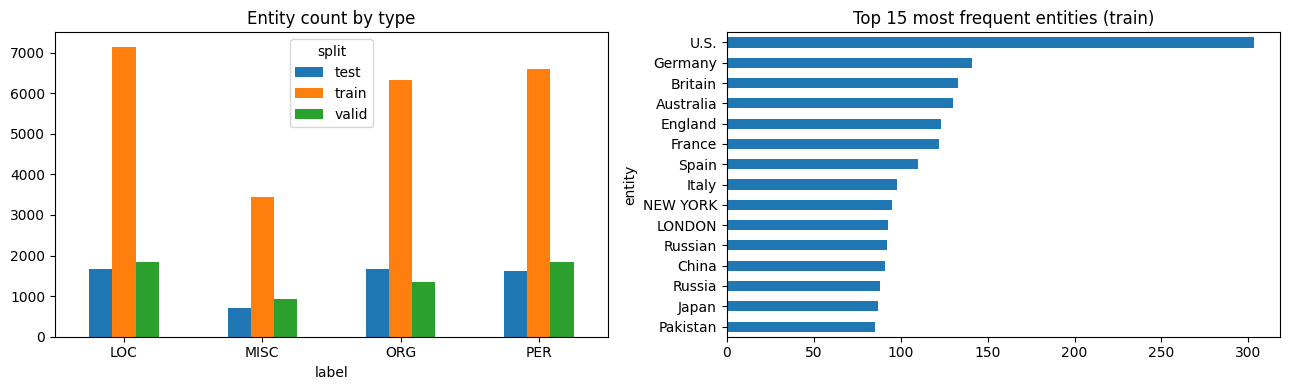

Avg. sentence length (tokens): 14.53


In [22]:
ent_rows = [(r.split, text, label) for r in df.itertuples() for text, label in r.entities]
ent_df = pd.DataFrame(ent_rows, columns=["split", "entity", "label"])

print("Entities per split and type:")
display(pd.crosstab(ent_df["label"], ent_df["split"], margins=True))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
pd.crosstab(ent_df["label"], ent_df["split"]).plot(kind="bar", ax=axes[0], rot=0, title="Entity count by type")
ent_df[ent_df.split == "train"]["entity"].value_counts().head(15).sort_values().plot(
    kind="barh", ax=axes[1], title="Top 15 most frequent entities (train)")
plt.tight_layout(); plt.show()

print("Avg. sentence length (tokens):", round(df["n_tokens"].mean(), 2))

## 4. Utilities: evaluation, prediction, visualization

* **Evaluation** = *entity-level exact match* (an entity is correct only if both boundaries and type are right) - the standard CoNLL metric.
* spaCy's pretrained models use the OntoNotes label scheme, so we map it to CoNLL labels:

| spaCy (OntoNotes) | CoNLL |
|---|---|
| PERSON | PER |
| ORG | ORG |
| GPE, LOC, FAC | LOC |
| NORP, EVENT, WORK_OF_ART, LAW, LANGUAGE, PRODUCT | MISC |
| DATE, TIME, MONEY, PERCENT, QUANTITY, CARDINAL, ORDINAL | *(ignored - not entities in CoNLL)* |

In [23]:
LABELS = ["PER", "ORG", "LOC", "MISC"]
LABEL_MAP = {"PERSON": "PER", "ORG": "ORG", "GPE": "LOC", "LOC": "LOC", "FAC": "LOC",
             "NORP": "MISC", "EVENT": "MISC", "WORK_OF_ART": "MISC", "LAW": "MISC",
             "LANGUAGE": "MISC", "PRODUCT": "MISC",
             # CoNLL labels map to themselves (used by the rule-based system)
             "PER": "PER", "MISC": "MISC"}

def evaluate(pred_spans, gold_sents):
    tp, fp, fn = Counter(), Counter(), Counter()
    for pred, (_, tags) in zip(pred_spans, gold_sents):
        gold, pred = set(bio_to_spans(tags)), set(pred)
        for s in pred & gold: tp[s[2]] += 1
        for s in pred - gold: fp[s[2]] += 1
        for s in gold - pred: fn[s[2]] += 1
    def prf(t, p, n):
        P = t / (t + p) if t + p else 0.0
        R = t / (t + n) if t + n else 0.0
        F = 2 * P * R / (P + R) if P + R else 0.0
        return P, R, F
    rows = {}
    for l in LABELS:
        rows[l] = prf(tp[l], fp[l], fn[l])
    rows["OVERALL (micro)"] = prf(sum(tp.values()), sum(fp.values()), sum(fn.values()))
    return pd.DataFrame(rows, index=["Precision", "Recall", "F1"]).T.round(4)

def predict(nlp, sents):
    # Feed the gold tokenization to spaCy so predictions align with CoNLL tokens.
    out = []
    for toks, _ in sents:
        doc = Doc(nlp.vocab, words=toks)
        for _, proc in nlp.pipeline:
            doc = proc(doc)
        out.append([(e.start, e.end, LABEL_MAP[e.label_]) for e in doc.ents if e.label_ in LABEL_MAP])
    return out

## 5. Rule-based NER (spaCy `EntityRuler`)
Two kinds of rules:
1. **Gazetteer** - every entity seen in the *training* set, labelled with its most frequent type.
2. **Heuristic patterns** - e.g. *Capitalized words + `Inc / Corp / Bank / Ltd`* -> ORG, *Capitalized words + `River / Lake / Island`* -> LOC.

In [24]:
# --- Gazetteer from the training set ---
gaz = defaultdict(Counter)
for toks, tags in train:
    for s, e, l in bio_to_spans(tags):
        gaz[tuple(toks[s:e])][l] += 1

def keep(key):
    # drop noisy single-token entries (punctuation / lowercase / 1 char)
    if len(key) == 1:
        t = key[0]
        return len(t) > 1 and t[0].isupper() and any(c.isalpha() for c in t)
    return True

gazetteer_patterns = [
    {"label": cnt.most_common(1)[0][0], "pattern": [{"ORTH": t} for t in key]}
    for key, cnt in gaz.items() if keep(key)
]
print("Gazetteer entries:", len(gazetteer_patterns))

# --- Heuristic patterns ---
ORG_SUFFIX = ["Inc", "Inc.", "Corp", "Corp.", "Ltd", "Ltd.", "Co", "Co.", "Plc", "PLC", "Bank", "Group",
              "Airlines", "Association", "Committee", "Party", "Ministry", "University", "Council", "Union"]
LOC_SUFFIX = ["River", "Lake", "Island", "Islands", "Mountains", "Sea", "Bay", "Valley"]

heuristic_patterns = [
    {"label": "ORG", "pattern": [{"IS_TITLE": True, "OP": "+"}, {"ORTH": {"IN": ORG_SUFFIX}}]},
    {"label": "LOC", "pattern": [{"IS_TITLE": True, "OP": "+"}, {"ORTH": {"IN": LOC_SUFFIX}}]},
]

def build_rule_nlp(use_heuristics=True):
    nlp_r = spacy.blank("en")
    ruler = nlp_r.add_pipe("entity_ruler", config={"overwrite_ents": True})
    ruler.add_patterns(gazetteer_patterns + (heuristic_patterns if use_heuristics else []))
    return nlp_r

nlp_rule_gaz  = build_rule_nlp(use_heuristics=False)
nlp_rule_full = build_rule_nlp(use_heuristics=True)

pred_gaz  = predict(nlp_rule_gaz,  test)
pred_rule = predict(nlp_rule_full, test)

print("\nRule-based: gazetteer only")
display(evaluate(pred_gaz, test))
print("Rule-based: gazetteer + heuristic patterns")
display(evaluate(pred_rule, test))

Gazetteer entries: 8053

Rule-based: gazetteer only


,Precision,Recall,F1
PER,0.5704,0.1429,0.2285
ORG,0.8202,0.5220,0.6380
LOC,0.7428,0.7842,0.7629
MISC,0.7671,0.6709,0.7158
OVERALL (micro),0.7498,0.5094,0.6066


Rule-based: gazetteer + heuristic patterns


,Precision,Recall,F1
PER,0.5732,0.1429,0.2287
ORG,0.8298,0.5400,0.6543
LOC,0.7453,0.7842,0.7642
MISC,0.7756,0.6695,0.7187
OVERALL (micro),0.7558,0.5145,0.6122


## 6. Model-based NER (pretrained spaCy models)

In [25]:
def load_model(name):
    try:
        return spacy.load(name)
    except OSError:
        try:
            from spacy.cli import download
            download(name)
            return spacy.load(name)
        except Exception as e:
            print(f"!! Could not load/download {name}: {e}")
            return None

MODEL_NAMES = ["en_core_web_sm", "en_core_web_md"]     # two models to compare
models = {n: load_model(n) for n in MODEL_NAMES}
models = {n: m for n, m in models.items() if m is not None}
print("Loaded:", list(models))

Loaded: ['en_core_web_sm', 'en_core_web_md']


In [26]:
model_preds, model_scores = {}, {}
for name, nlp_m in models.items():
    print(f"Predicting with {name} ...")
    model_preds[name] = predict(nlp_m, test)
    model_scores[name] = evaluate(model_preds[name], test)
    print(f"\n{name}")
    display(model_scores[name])

Predicting with en_core_web_sm ...

en_core_web_sm


,Precision,Recall,F1
PER,0.7164,0.5875,0.6456
ORG,0.4295,0.3101,0.3601
LOC,0.7698,0.7296,0.7492
MISC,0.6746,0.5641,0.6144
OVERALL (micro),0.6559,0.5450,0.5953


Predicting with en_core_web_md ...

en_core_web_md


,Precision,Recall,F1
PER,0.7643,0.6357,0.6941
ORG,0.4497,0.3281,0.3794
LOC,0.6799,0.8010,0.7355
MISC,0.7163,0.5826,0.6426
OVERALL (micro),0.6515,0.5875,0.6178


## 7. Highlight & categorize entities in text (displacy)

In [27]:
COLORS = {"PER": "#feca74", "ORG": "#7aecec", "LOC": "#aa9cfc", "MISC": "#ff9561"}
DISPLAY_OPTS = {"ents": LABELS, "colors": COLORS}

NO_SPACE_BEFORE = {".", ",", ";", ":", "!", "?", ")", "]", "%", "'s", "n't", "'", "''"}

def tokens_to_doc(vocab, toks, spans):
    spaces = [(i + 1 < len(toks) and toks[i + 1] not in NO_SPACE_BEFORE) and toks[i] not in {"(", "["}
              for i in range(len(toks))]
    doc = Doc(vocab, words=toks, spaces=spaces)
    doc.ents = [Span(doc, s, e, label=l) for s, e, l in spans]
    return doc

def show(doc, title=""):
    if title:
        print(title)
    displacy.render(doc, style="ent", jupyter=True, options=DISPLAY_OPTS)

def text_to_doc(nlp, text):
    # Run on raw text (spaCy tokenizer) and map labels to CoNLL labels.
    doc = nlp(text)
    doc.ents = [Span(doc, e.start, e.end, label=LABEL_MAP[e.label_]) for e in doc.ents if e.label_ in LABEL_MAP]
    return doc

In [28]:
# A few test sentences: gold vs. rule-based vs. each spaCy model
base = list(models.values())[0].vocab if models else nlp_rule_full.vocab
idxs = [i for i, (t, tg) in enumerate(test) if 12 <= len(t) <= 25 and len(bio_to_spans(tg)) >= 3][:4]

for i in idxs:
    toks, tags = test[i]
    print("=" * 100)
    show(tokens_to_doc(base, toks, bio_to_spans(tags)), "GOLD")
    show(tokens_to_doc(base, toks, pred_rule[i]), "RULE-BASED")
    for name in models:
        show(tokens_to_doc(base, toks, model_preds[name][i]), name)

GOLD


RULE-BASED


en_core_web_sm


en_core_web_md


GOLD


...

en_core_web_md


GOLD


RULE-BASED


en_core_web_sm


en_core_web_md


### Free text - try your own news article
Edit `article` below.

In [29]:
article = (
    "Apple CEO Tim Cook announced on Tuesday in California that the company will open a new office in Cairo, Egypt. "
    "The European Commission and Reuters said Microsoft and Google would also expand in Germany, "
    "while the United Nations praised the Egyptian government in a statement from New York."
)

print("--- Rule-based ---")
displacy.render(text_to_doc(nlp_rule_full, article), style="ent", jupyter=True, options=DISPLAY_OPTS)
for name, nlp_m in models.items():
    print(f"--- {name} ---")
    displacy.render(text_to_doc(nlp_m, article), style="ent", jupyter=True, options=DISPLAY_OPTS)

--- Rule-based ---


--- en_core_web_sm ---


--- en_core_web_md ---


In [30]:
# Entities as a table (Pandas) for the model of your choice
def entities_table(nlp, text):
    doc = text_to_doc(nlp, text)
    return pd.DataFrame([(e.text, e.label_, e.start_char, e.end_char) for e in doc.ents],
                        columns=["entity", "label", "start_char", "end_char"])

for name, nlp_m in models.items():
    print(name)
    display(entities_table(nlp_m, article))

en_core_web_sm


,entity,label,start_char,end_char
0,Apple,ORG,0,5
1,Tim Cook,PER,10,18
2,California,LOC,43,53
3,Cairo,LOC,97,102
4,Egypt,LOC,104,109
5,The European Commission,ORG,111,134
6,Reuters,ORG,139,146
7,Microsoft,ORG,152,161
8,Google,ORG,166,172
9,Germany,LOC,194,201


en_core_web_md


,entity,label,start_char,end_char
0,Apple,ORG,0,5
1,Tim Cook,PER,10,18
2,California,LOC,43,53
3,Cairo,LOC,97,102
4,Egypt,LOC,104,109
5,The European Commission,ORG,111,134
6,Reuters,ORG,139,146
7,Microsoft,ORG,152,161
8,Google,ORG,166,172
9,Germany,LOC,194,201


## 8. Bonus: comparing the systems

F1 per entity type (test set)


,Rule-based (gazetteer),Rule-based (gaz + heuristics),en_core_web_sm,en_core_web_md
PER,0.2285,0.2287,0.6456,0.6941
ORG,0.6380,0.6543,0.3601,0.3794
LOC,0.7629,0.7642,0.7492,0.7355
MISC,0.7158,0.7187,0.6144,0.6426
OVERALL (micro),0.6066,0.6122,0.5953,0.6178


Overall micro scores


,Precision,Recall,F1
Rule-based (gazetteer),0.7498,0.5094,0.6066
Rule-based (gaz + heuristics),0.7558,0.5145,0.6122
en_core_web_sm,0.6559,0.5450,0.5953
en_core_web_md,0.6515,0.5875,0.6178


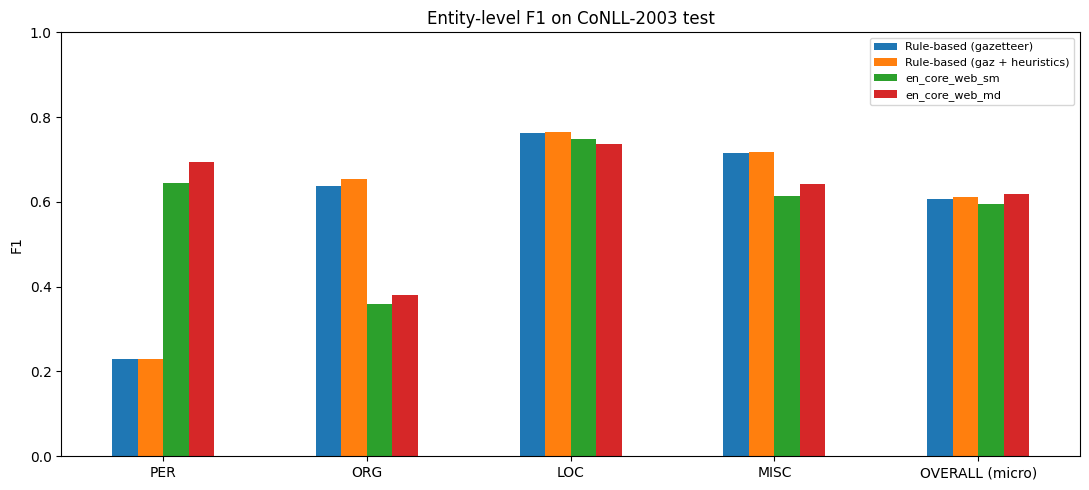

In [31]:
systems = {"Rule-based (gazetteer)": evaluate(pred_gaz, test),
           "Rule-based (gaz + heuristics)": evaluate(pred_rule, test)}
systems.update(model_scores)

# F1 per entity type
f1_table = pd.DataFrame({name: sc["F1"] for name, sc in systems.items()})
print("F1 per entity type (test set)")
display(f1_table)

# Overall summary
summary = pd.DataFrame({name: sc.loc["OVERALL (micro)"] for name, sc in systems.items()}).T
print("Overall micro scores")
display(summary)

f1_table.plot(kind="bar", figsize=(11, 5), rot=0, title="Entity-level F1 on CoNLL-2003 test")
plt.ylabel("F1"); plt.ylim(0, 1); plt.legend(loc="upper right", fontsize=8); plt.tight_layout(); plt.show()

In [32]:
# Where do the two spaCy models disagree?
if len(models) >= 2:
    a, b = list(models)[:2]
    diff = [i for i in range(len(test)) if set(model_preds[a][i]) != set(model_preds[b][i])]
    print(f"{a} vs {b}: predictions differ in {len(diff):,} / {len(test):,} sentences "
          f"({len(diff)/len(test):.1%})")
    for i in diff[:3]:
        toks, tags = test[i]
        print("=" * 100)
        show(tokens_to_doc(base, toks, bio_to_spans(tags)), "GOLD")
        show(tokens_to_doc(base, toks, model_preds[a][i]), a)
        show(tokens_to_doc(base, toks, model_preds[b][i]), b)

en_core_web_sm vs en_core_web_md: predictions differ in 1,463 / 3,453 sentences (42.4%)
GOLD


en_core_web_sm


en_core_web_md


GOLD


en_core_web_sm


en_core_web_md


GOLD


en_core_web_sm


en_core_web_md


In [33]:
# Error analysis: most frequently missed gold entities (false negatives) per system
def top_misses(pred_spans, n=10):
    c = Counter()
    for pred, (toks, tags) in zip(pred_spans, test):
        for s, e, l in set(bio_to_spans(tags)) - set(pred):
            c[(" ".join(toks[s:e]), l)] += 1
    return pd.DataFrame(c.most_common(n), columns=["(entity, gold label)", "times missed"])

print("Rule-based - top misses"); display(top_misses(pred_rule))
for name in models:
    print(f"{name} - top misses"); display(top_misses(model_preds[name]))

Rule-based - top misses


,"(entity, gold label)",times missed
0,"(WTO, ORG)",19
1,"(Santa Fe, ORG)",16
2,"(Norilsk, ORG)",15
3,"(Newmont, ORG)",14
4,"(Bre-X, ORG)",13
5,"(Czech, LOC)",12
6,"(Lara, PER)",10
7,"(Albright, PER)",9
8,"(Major, PER)",9
9,"(Mills, PER)",9


en_core_web_sm - top misses


,"(entity, gold label)",times missed
0,"(Barcelona, ORG)",22
1,"(Real Madrid, ORG)",14
2,"(Newmont, ORG)",14
3,"(United States, LOC)",13
4,"(Czech, LOC)",12
5,"(GMT, MISC)",11
6,"(Lara, PER)",10
7,"(WORLD CUP, MISC)",10
8,"(Internet, MISC)",10
9,"(World Cup, MISC)",9


en_core_web_md - top misses


,"(entity, gold label)",times missed
0,"(Barcelona, ORG)",22
1,"(United States, LOC)",13
2,"(Czech, LOC)",12
3,"(Bre-X, ORG)",12
4,"(Norilsk, ORG)",11
5,"(Newmont, ORG)",10
6,"(Internet, MISC)",10
7,"(GMT, MISC)",9
8,"(Real Madrid, ORG)",9
9,"(USDA, ORG)",9


## 9. Conclusions

* **Rule-based (gazetteer + patterns)** is fast, transparent and very precise on entities it has seen, but its **recall collapses on unseen entities** - it can only find what is in the training gazetteer, and it cannot use context to disambiguate (e.g. *Washington* as PER / LOC / ORG).
* **Model-based (spaCy)** generalizes to unseen names thanks to context and word shape/embeddings. Part of the remaining error is **label-scheme mismatch**: spaCy is trained on OntoNotes, whose guidelines differ from CoNLL (e.g. sports teams, nationalities, MISC).
* **`en_core_web_md` vs `en_core_web_sm`:** compare the table in section 8 - `md` ships with static word vectors, which usually helps on rarer names.
* **Next steps:** fine-tune a spaCy model on the CoNLL train set (`spacy train`) so labels match exactly, or combine both approaches (model first, then `EntityRuler` for domain-specific terms).

## 10. Train a custom spaCy NER model on CoNLL-2003

Unlike the generic spaCy models above, this model learns the exact CoNLL labels from the training split. We monitor validation F1 and keep the best checkpoint. The test split is reserved for final evaluation.

In [34]:
import random, copy, time
from pathlib import Path
from spacy.training import Example
from spacy.util import minibatch, compounding

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Start with a blank English pipeline so no pretrained NER label scheme leaks in.
nlp_custom = spacy.blank("en")
ner = nlp_custom.add_pipe("ner")
for label in LABELS:
    ner.add_label(label)

def to_training_example(nlp, sentence):
    tokens, tags = sentence
    doc = Doc(nlp.vocab, words=tokens)
    char_entities = []
    for start, end, label in bio_to_spans(tags):
        # CoNLL spans are token-index spans; spaCy training examples use character offsets.
        start_char = doc[start].idx
        end_char = doc[end - 1].idx + len(doc[end - 1])
        char_entities.append((start_char, end_char, label))
    return Example.from_dict(doc, {"entities": char_entities})

train_examples = [to_training_example(nlp_custom, s) for s in train]
valid_examples = [to_training_example(nlp_custom, s) for s in valid]
print(f"Training examples: {len(train_examples):,}; validation examples: {len(valid_examples):,}")


Training examples: 14,041; validation examples: 3,250


### Training configuration

The defaults are intended to be practical in a hosted notebook. If runtime is limited, reduce `N_EPOCHS`; if the validation score is still improving, allow more epochs. The best model is selected by validation F1, not by the test score.

In [35]:
N_EPOCHS = 20
DROPOUT = 0.2
BATCH_START = 32
BATCH_STOP = 128
PATIENCE = 5

optimizer = nlp_custom.initialize(get_examples=lambda: iter(train_examples))
best_valid_f1 = -1.0
best_epoch = 0
wait = 0
history = []
best_model_dir = Path("conll_custom_ner_best")

def evaluate_custom_on_split(nlp, split):
    predictions = predict(nlp, split)
    scores = evaluate(predictions, split)
    return float(scores.loc["OVERALL (micro)", "F1"]), scores

start_time = time.time()
for epoch in range(1, N_EPOCHS + 1):
    random.shuffle(train_examples)
    losses = {}
    batches = minibatch(train_examples, size=compounding(BATCH_START, BATCH_STOP, 1.001))
    for batch in batches:
        nlp_custom.update(batch, sgd=optimizer, drop=DROPOUT, losses=losses)

    valid_f1, valid_scores = evaluate_custom_on_split(nlp_custom, valid)
    history.append({"epoch": epoch, "loss": sum(losses.values()), "valid_f1": valid_f1})
    print(f"Epoch {epoch:02d} | loss={sum(losses.values()):.2f} | validation F1={valid_f1:.4f}")

    if valid_f1 > best_valid_f1:
        best_valid_f1 = valid_f1
        best_epoch = epoch
        wait = 0
        nlp_custom.to_disk(best_model_dir)
    else:
        wait += 1
        if wait >= PATIENCE:
            print(f"Early stopping: validation F1 did not improve for {PATIENCE} epochs.")
            break

print(f"Training time: {(time.time()-start_time)/60:.1f} minutes")
print(f"Best epoch: {best_epoch}; best validation F1: {best_valid_f1:.4f}")

# Reload the best validation checkpoint rather than keeping the final epoch.
nlp_custom = spacy.load(best_model_dir)
display(pd.DataFrame(history))


Epoch 01 | loss=23138.33 | validation F1=0.7697
Epoch 02 | loss=9349.73 | validation F1=0.8252
Epoch 03 | loss=6815.86 | validation F1=0.8491
Epoch 04 | loss=5069.83 | validation F1=0.8549
Epoch 05 | loss=4068.38 | validation F1=0.8599
Epoch 06 | loss=3686.58 | validation F1=0.8666
Epoch 07 | loss=3117.17 | validation F1=0.8666
Epoch 08 | loss=2713.68 | validation F1=0.8679
Epoch 09 | loss=2475.59 | validation F1=0.8641
Epoch 10 | loss=2354.83 | validation F1=0.8684
Epoch 11 | loss=2141.39 | validation F1=0.8667
Epoch 12 | loss=1902.67 | validation F1=0.8750
Epoch 13 | loss=1905.50 | validation F1=0.8750
Epoch 14 | loss=1668.73 | validation F1=0.8717
Epoch 15 | loss=1617.75 | validation F1=0.8800
Epoch 16 | loss=1460.04 | validation F1=0.8759
Epoch 17 | loss=1348.76 | validation F1=0.8739
Epoch 18 | loss=1399.24 | validation F1=0.8780
Epoch 19 | loss=1298.22 | validation F1=0.8761
Epoch 20 | loss=1168.62 | validation F1=0.8747
Early stopping: validation F1 did not improve for 5 epochs.

,epoch,loss,valid_f1
0,1,23138.330078,0.7697
1,2,9349.726562,0.8252
2,3,6815.859375,0.8491
3,4,5069.826172,0.8549
4,5,4068.376953,0.8599
5,6,3686.579102,0.8666
6,7,3117.171631,0.8666
7,8,2713.678223,0.8679
8,9,2475.589600,0.8641
9,10,2354.831055,0.8684


## 11. Final evaluation and comparison

This section evaluates the selected checkpoint on the held-out test split. The test score is reported once as the final estimate. All comparisons use exact entity boundaries and entity type.

Custom CoNLL-trained spaCy model — TEST


,Precision,Recall,F1
PER,0.8538,0.8237,0.8385
ORG,0.7891,0.7435,0.7657
LOC,0.8524,0.8687,0.8605
MISC,0.7113,0.7721,0.7404
OVERALL (micro),0.8158,0.8070,0.8114


Final test-set comparison (sorted by micro F1)


,Precision,Recall,F1
Custom spaCy NER (trained on CoNLL),0.8158,0.8070,0.8114
en_core_web_md,0.6515,0.5875,0.6178
Rule-based (gazetteer + heuristics),0.7558,0.5145,0.6122
Rule-based (gazetteer),0.7498,0.5094,0.6066
en_core_web_sm,0.6559,0.5450,0.5953


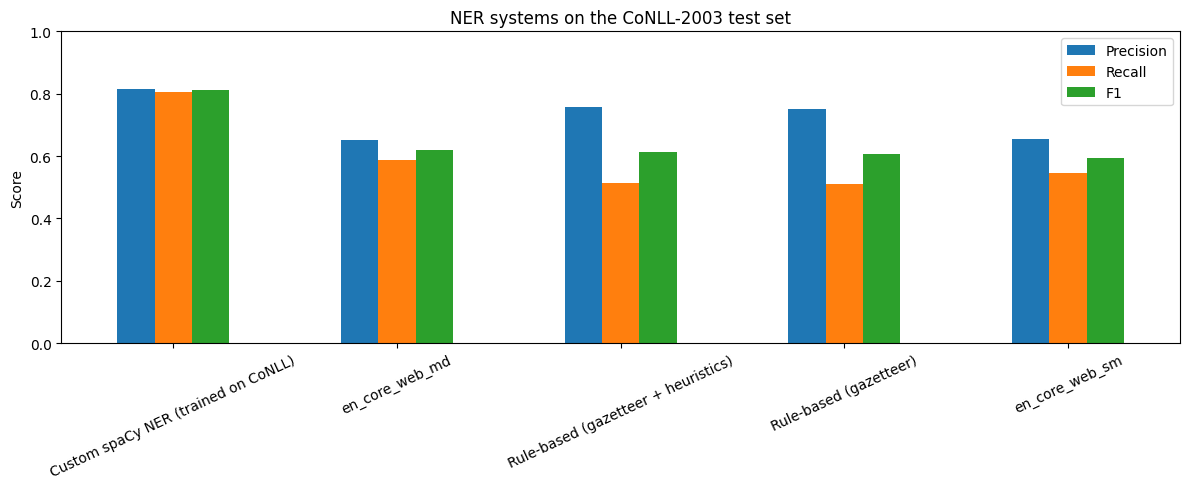

In [36]:
custom_test_preds = predict(nlp_custom, test)
custom_test_scores = evaluate(custom_test_preds, test)
print("Custom CoNLL-trained spaCy model — TEST")
display(custom_test_scores)

comparison = {
    "Rule-based (gazetteer)": evaluate(pred_gaz, test),
    "Rule-based (gazetteer + heuristics)": evaluate(pred_rule, test),
}
comparison.update(model_scores)
comparison["Custom spaCy NER (trained on CoNLL)"] = custom_test_scores
comparison_summary = pd.DataFrame({name: score.loc["OVERALL (micro)"] for name, score in comparison.items()}).T
comparison_summary = comparison_summary.sort_values("F1", ascending=False)
print("Final test-set comparison (sorted by micro F1)")
display(comparison_summary)

ax = comparison_summary[["Precision", "Recall", "F1"]].plot(kind="bar", figsize=(12, 5), rot=25)
ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title("NER systems on the CoNLL-2003 test set")
plt.tight_layout()
plt.show()


## 12. Per-entity results and visual inspection

In [37]:
print("Custom model F1 by entity type")
display(custom_test_scores.loc[["PER", "ORG", "LOC", "MISC"], ["Precision", "Recall", "F1"]])

# Inspect examples with missed or spurious entities.
def entity_texts(spans, tokens):
    return [(" ".join(tokens[s:e]), label) for s, e, label in spans]

def show_custom_errors(n=10):
    shown = 0
    for (tokens, tags), pred in zip(test, custom_test_preds):
        gold = set(bio_to_spans(tags))
        pred_set = set(pred)
        if gold != pred_set:
            print("TEXT:", " ".join(tokens))
            print("GOLD:", entity_texts(sorted(gold), tokens))
            print("PRED:", entity_texts(sorted(pred_set), tokens))
            print("MISSED:", entity_texts(sorted(gold - pred_set), tokens))
            print("SPURIOUS:", entity_texts(sorted(pred_set - gold), tokens))
            print("-" * 90)
            shown += 1
            if shown >= n:
                break
show_custom_errors()


Custom model F1 by entity type


,Precision,Recall,F1
PER,0.8538,0.8237,0.8385
ORG,0.7891,0.7435,0.7657
LOC,0.8524,0.8687,0.8605
MISC,0.7113,0.7721,0.7404


TEXT: SOCCER - JAPAN GET LUCKY WIN , CHINA IN SURPRISE DEFEAT .
GOLD: [('JAPAN', 'LOC'), ('CHINA', 'PER')]
PRED: [('JAPAN', 'LOC'), ('CHINA', 'LOC')]
MISSED: [('CHINA', 'PER')]
SPURIOUS: [('CHINA', 'LOC')]
------------------------------------------------------------------------------------------
TEXT: AL-AIN , United Arab Emirates 1996-12-06
GOLD: [('AL-AIN', 'LOC'), ('United Arab Emirates', 'LOC')]
PRED: [('United Arab Emirates', 'ORG')]
MISSED: [('AL-AIN', 'LOC'), ('United Arab Emirates', 'LOC')]
SPURIOUS: [('United Arab Emirates', 'ORG')]
------------------------------------------------------------------------------------------
TEXT: China controlled most of the match and saw several chances missed until the 78th minute when Uzbek striker Igor Shkvyrin took advantage of a misdirected defensive header to lob the ball over the advancing Chinese keeper and into an empty net .
GOLD: [('China', 'LOC'), ('Uzbek', 'MISC'), ('Igor Shkvyrin', 'PER'), ('Chinese', 'MISC')]
PRED: [('China', 'LO

In [38]:
# displaCy visualization for a held-out test sentence using the custom model
example_idx = 0
tokens, gold_tags = test[example_idx]
doc_custom = Doc(nlp_custom.vocab, words=tokens)
for _, component in nlp_custom.pipeline:
    doc_custom = component(doc_custom)
print("Custom model entities:", [(e.text, e.label_) for e in doc_custom.ents])
displacy.render(doc_custom, style="ent", jupyter=True, options={"ents": LABELS})


Custom model entities: [('JAPAN', 'LOC'), ('CHINA', 'LOC')]


## 13. Save the trained model

The model is saved in `conll_custom_ner_best/` in the notebook working directory. Download or zip this directory if you need to submit the trained model alongside the notebook. The notebook itself remains reproducible from the CoNLL data and training cells.

In [39]:
import shutil
MODEL_OUTPUT = "conll_custom_ner_best"
ZIP_PATH = shutil.make_archive("conll_custom_ner_best", "zip", root_dir=MODEL_OUTPUT)
print("Saved model directory:", MODEL_OUTPUT)
print("Model archive:", ZIP_PATH)


Saved model directory: conll_custom_ner_best
Model archive: /kaggle/working/conll_custom_ner_best.zip


## Updated conclusion

- The rule-based systems provide interpretable baselines but struggle with unseen entities.
- The two pretrained spaCy models are useful comparisons, but their OntoNotes label conventions do not perfectly match CoNLL-2003.
- The custom model is trained on CoNLL-2003 and therefore learns the target labels directly. Report its actual held-out test F1 after running the notebook; do not promise a score in advance.
- Use the validation set for model selection and the test set only for the final comparison.
